# Stage 5 : Web application with calibrated scores and Grad-CAM explanations

**What this notebook does**
1. Loads the final ViT (the same model used in Stage 4).
2. **Calibrates** its scores with temperature scaling on the validation set (the raw scores were overconfident).
3. Measures what "normal" input images look like, so the app can **warn about unusual (out-of-distribution) images**.
4. Writes the complete app into `forestnet_project/app/` (app code, model, settings, examples, requirements).
5. **Tests** the app with normal, invalid and out-of-distribution inputs and measures CPU latency.
6. Launches the app from Colab (temporary public link) and, optionally, publishes it on **Hugging Face Spaces**.

**Rules:** validation data only - the test set is still untouched. (used GUP)

## 0. Setup

In [ ]:
import os, sys, json, time, hashlib, zipfile, io, importlib, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd

SEED = 42
IN_COLAB = "google.colab" in sys.modules
if os.environ.get("FORESTNET_BASE"):
    BASE = Path(os.environ["FORESTNET_BASE"])
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/forestnet_project")
else:
    BASE = Path("./forestnet_project")
RUNS = BASE / "outputs" / "stage3" / "runs"; CACHE = BASE / "cache"
OUT5 = BASE / "outputs" / "stage5"; OUT5.mkdir(parents=True, exist_ok=True)
APP_DIR = BASE / "app"; (APP_DIR / "examples").mkdir(parents=True, exist_ok=True)
print("Project folder:", BASE, "| app folder:", APP_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/drive/MyDrive/forestnet_project | app folder: /content/drive/MyDrive/forestnet_project/app


In [ ]:
!pip -q install timm gradio

import torch, torch.nn as nn, torch.nn.functional as F
import timm, gradio as gr
import matplotlib.pyplot as plt
from PIL import Image
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| timm", timm.__version__, "| gradio", gr.__version__, "| device", DEV)

torch 2.11.0+cpu | timm 1.0.30 | gradio 6.30.0 | device cpu


## 1. Split, data and the final ViT

In [ ]:
def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

meta = json.load(open(BASE / "outputs" / "dataset_meta.json"))
assert sha256(BASE / "outputs" / "split_manifest.csv") == meta["manifest_sha256"], "Split changed!"
man = pd.read_csv(BASE / "outputs" / "split_manifest.csv").sort_values("example_path").reset_index(drop=True)
CLASSES = sorted(man["merged_label"].unique()); CLS2ID = {c: i for i, c in enumerate(CLASSES)}
man["y"] = man["merged_label"].map(CLS2ID)
TR_IDX = np.where(man.split == "train")[0]; VA_IDX = np.where(man.split == "val")[0]
COMP = np.load(CACHE / "comp_full.npy"); IMG = COMP.shape[1]

choice = json.load(open(BASE / "outputs" / "stage4" / "xai_model_choice.json"))
RUN_ID, CFG = choice["run_id"], choice["cfg"]
TIMM_VIT = "vit_small_patch16_224.augreg_in21k_ft_in1k"

class ViTClassifier(nn.Module):
    def __init__(self, depth=12, hidden=256, drop=0.2):
        super().__init__()
        self.backbone = timm.create_model(TIMM_VIT, pretrained=False, num_classes=0)
        self.backbone.blocks = self.backbone.blocks[:depth]
        d = self.backbone.num_features
        self.head = nn.Sequential(nn.LayerNorm(2 * d), nn.Dropout(drop), nn.Linear(2 * d, hidden),
                                  nn.GELU(), nn.Dropout(drop), nn.Linear(hidden, len(CLASSES)))
    def forward(self, x):
        t = self.backbone.forward_features(x)
        return self.head(torch.cat([t[:, 0], t[:, 1:].mean(1)], dim=1))

model = ViTClassifier(CFG["depth"], CFG["hidden"], CFG["drop"])
state = torch.load(RUNS / RUN_ID / "best.pt", map_location="cpu")
model.load_state_dict(state); model = model.to(DEV).eval()
MEAN = torch.tensor(meta["train_rgb_norm"]["mean"]).view(1, 3, 1, 1)
STD = torch.tensor(meta["train_rgb_norm"]["std"]).view(1, 3, 1, 1)

@torch.no_grad()
def logits_of(imgs_u8, bs=64):
    out = []
    for b in range(0, len(imgs_u8), bs):
        x = torch.from_numpy(imgs_u8[b:b + bs]).permute(0, 3, 1, 2).float() / 255.0
        out.append(model(((x - MEAN) / STD).to(DEV)).float().cpu())
    return torch.cat(out)

VAL_LOGITS = logits_of(COMP[VA_IDX]); VAL_Y = torch.tensor(man.y.values[VA_IDX])
print("Model:", RUN_ID, "| val accuracy", round((VAL_LOGITS.argmax(1) == VAL_Y).float().mean().item(), 4))

Model: S3-VIT-FINAL-s43 | val accuracy 0.814


## 2. Calibration : temperature scaling
The raw softmax scores were overconfident (Stage 4: mean confidence 0.94 vs accuracy 0.81). **Temperature scaling**
divides the logits by one number **T** before the softmax. T > 1 softens over-confident scores. It does **not**
change which class is predicted (so accuracy and macro-F1 stay the same), only how confident the scores are.
T is chosen to minimise the negative log-likelihood on the **validation** set.


In [ ]:
def ece(probs, y, n_bins=10):
    conf, pred = probs.max(1); acc = (pred == y).float(); e = 0.0
    edges = torch.linspace(0, 1, n_bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        s = (conf > lo) & (conf <= hi)
        if s.any():
            e += s.float().mean() * (acc[s].mean() - conf[s].mean()).abs()
    return float(e)

log_t = torch.zeros(1, requires_grad=True)
opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)
def closure():
    opt.zero_grad(); loss = F.cross_entropy(VAL_LOGITS / log_t.exp(), VAL_Y); loss.backward(); return loss
opt.step(closure)
TEMP = float(log_t.detach().exp().item())
p_raw, p_cal = F.softmax(VAL_LOGITS, 1), F.softmax(VAL_LOGITS / TEMP, 1)
calib = pd.DataFrame({"raw": {"NLL": F.cross_entropy(VAL_LOGITS, VAL_Y).item(), "ECE": ece(p_raw, VAL_Y),
                              "mean confidence": p_raw.max(1).values.mean().item(),
                              "share > 0.99": (p_raw.max(1).values > 0.99).float().mean().item()},
                      f"temperature-scaled (T={TEMP:.2f})": {"NLL": F.cross_entropy(VAL_LOGITS / TEMP, VAL_Y).item(),
                              "ECE": ece(p_cal, VAL_Y), "mean confidence": p_cal.max(1).values.mean().item(),
                              "share > 0.99": (p_cal.max(1).values > 0.99).float().mean().item()}}).round(3)
calib.loc["accuracy"] = round((VAL_LOGITS.argmax(1) == VAL_Y).float().mean().item(), 3)
display(calib); calib.to_csv(OUT5 / "calibration.csv")

,raw,temperature-scaled (T=2.14)
NLL,0.832,0.580
ECE,0.132,0.039
mean confidence,0.939,0.814
share > 0.99,0.584,0.000
accuracy,0.814,0.814


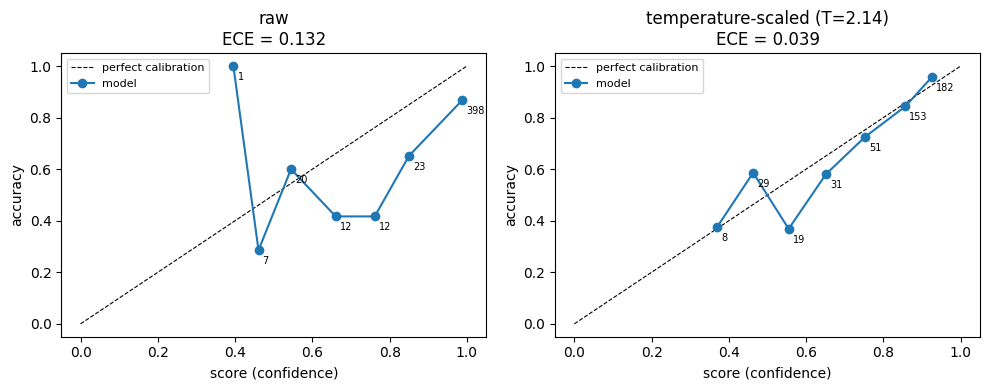

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, p) in zip(axes, [("raw", p_raw), (f"temperature-scaled (T={TEMP:.2f})", p_cal)]):
    conf, pred = p.max(1); acc = (pred == VAL_Y).float(); edges = np.linspace(0, 1, 11); xs, ys, ns = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        s = (conf > lo) & (conf <= hi)
        if s.any():
            xs.append(conf[s].mean().item()); ys.append(acc[s].mean().item()); ns.append(int(s.sum()))
    ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="perfect calibration")
    ax.plot(xs, ys, "o-", label="model")
    for x_, y_, n_ in zip(xs, ys, ns):
        ax.annotate(str(n_), (x_, y_), fontsize=7, xytext=(3, -10), textcoords="offset points")
    ax.set_title(f"{name}\nECE = {ece(p, VAL_Y):.3f}"); ax.set_xlabel("score (confidence)"); ax.set_ylabel("accuracy")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT5 / "reliability_diagram.png", dpi=150); plt.show()

### Low-certainty threshold
Predictions whose calibrated score is below a threshold are flagged in the app as **"refer for manual review"**.
The table shows, for several thresholds, how many validation predictions would be flagged and how accurate the
flagged and unflagged groups are.

In [ ]:
conf_c = p_cal.max(1).values; correct = (p_cal.argmax(1) == VAL_Y)
thr_tab = pd.DataFrame([{"threshold": t, "share flagged": (conf_c < t).float().mean().item(),
                         "accuracy of flagged": correct[conf_c < t].float().mean().item() if (conf_c < t).any() else np.nan,
                         "accuracy of not flagged": correct[conf_c >= t].float().mean().item()}
                        for t in (0.5, 0.6, 0.7, 0.8, 0.9)]).round(3)
display(thr_tab); thr_tab.to_csv(OUT5 / "low_confidence_thresholds.csv", index=False)
LOW_CONF = 0.60          # <<< your choice after reading the table

,threshold,share flagged,accuracy of flagged,accuracy of not flagged
0,0.5,0.078,0.541,0.837
1,0.6,0.118,0.482,0.859
2,0.7,0.184,0.517,0.881
3,0.8,0.292,0.594,0.904
4,0.9,0.615,0.725,0.956


## 3. What do normal inputs look like? (for out-of-distribution warnings)
For every **training** composite we measure three simple statistics of the full image: mean brightness, contrast
(standard deviation) and green ratio (green channel ÷ overall mean). The app warns when an uploaded image falls
outside the range covering 99% of training images (0.5th–99.5th percentile). This is a simple screening check, not a
guarantee: it catches clearly different inputs (photos, brightened images, clouds), not subtle ones.

In [ ]:
def img_stats(img):
    img = img.astype(np.float32)
    return {"mean_brightness": img.mean(), "contrast": img.std(), "green_ratio": img[..., 1].mean() / (img.mean() + 1e-6)}

ZIP = BASE / "data" / "ForestNetDataset.zip"
zf = zipfile.ZipFile(ZIP)
PREFIX = next(n for n in zf.namelist() if n.endswith("train.csv"))[:-len("train.csv")]
def read_png(example_path, name="composite.png"):
    return np.asarray(Image.open(io.BytesIO(zf.read(f"{PREFIX}{example_path}/images/visible/{name}"))).convert("RGB"))

t0 = time.time()
tr_stats = pd.DataFrame([img_stats(read_png(p)) for p in man.example_path.values[TR_IDX]])
OOD_RANGES = {k: [float(tr_stats[k].quantile(0.005)), float(tr_stats[k].quantile(0.995))] for k in tr_stats}
va_stats = pd.DataFrame([img_stats(read_png(p)) for p in man.example_path.values[VA_IDX]])
false_alarm = np.mean([any(not (OOD_RANGES[k][0] <= r[k] <= OOD_RANGES[k][1]) for k in OOD_RANGES) for _, r in va_stats.iterrows()])
print(f"({time.time() - t0:.0f}s) OOD ranges from training images:", {k: [round(a, 3) for a in v] for k, v in OOD_RANGES.items()})
print(f"Share of validation images that would trigger the warning (false alarms): {false_alarm:.1%}")

(19s) OOD ranges from training images: {'mean_brightness': [7.121, 49.548], 'contrast': [5.531, 31.165], 'green_ratio': [1.077, 1.919]}
Share of validation images that would trigger the warning (false alarms): 5.7%


## 4. Write the app bundle into `forestnet_project/app/`
| File | Content |
|---|---|
| `app.py` | the web application (frontend + backend) |
| `model.pt` | the trained ViT weights |
| `config.json` | classes, actions, temperature, threshold, normalisation, OOD ranges, model settings |
| `examples/` | four **validation** images (one per class) to try the app |
| `requirements.txt`, `README.md` | what Hugging Face Spaces needs to run the app |

In [ ]:
ACTIONS = {"Plantation": "Check permits / concession status; refer for enforcement if the clearing is not permitted.",
           "Smallholder agriculture": "Refer to community-support programmes.",
           "Grassland shrubland": "Flag the area for restoration and fire monitoring.",
           "Other": "Send for field inspection (possible mining, logging roads, fish ponds or secondary forest)."}
DISPLAY = {"Plantation": "Plantation", "Smallholder agriculture": "Smallholder agriculture",
           "Grassland shrubland": "Grassland / shrubland", "Other": "Other (mining, logging, fish pond, secondary forest)"}
config = {"classes": CLASSES, "display_names": DISPLAY, "actions": ACTIONS, "temperature": TEMP,
          "low_confidence_threshold": LOW_CONF, "img_size": int(IMG), "mean": meta["train_rgb_norm"]["mean"],
          "std": meta["train_rgb_norm"]["std"], "ood_ranges": OOD_RANGES, "timm_name": TIMM_VIT,
          "depth": CFG["depth"], "hidden": CFG["hidden"], "drop": CFG["drop"], "n_train": int(len(TR_IDX)),
          "val_macro_f1": float(choice["val_macro_f1"]), "model_run_id": RUN_ID,
          "created": time.strftime("%Y-%m-%d %H:%M")}
json.dump(config, open(APP_DIR / "config.json", "w"), indent=2)
torch.save({k: v.cpu() for k, v in state.items()}, APP_DIR / "model.pt")

APP_PY = r'''"""
ForestNet driver classifier — web application (Question 4 / 5.b)

Frontend + backend in one Gradio app. Every prediction is computed by the trained ViT at request time:
  upload image -> input checks -> preprocessing (as in training) -> ViT -> temperature-scaled scores
  -> recommended action -> Grad-CAM explanation.
Files needed next to this script: config.json, model.pt (and optionally examples/*.png).
"""
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import gradio as gr
from PIL import Image
import matplotlib
matplotlib.use("Agg")
from matplotlib import cm

HERE = Path(__file__).resolve().parent
CFG = json.load(open(HERE / "config.json"))
CLASSES = CFG["classes"]                         # alphabetical order used in training
ACTIONS = CFG["actions"]
T = float(CFG["temperature"])                    # temperature fitted on the validation set
LOW_CONF = float(CFG["low_confidence_threshold"])
IMG = int(CFG["img_size"])
MEAN = np.array(CFG["mean"], dtype=np.float32)   # training-set channel mean (0-1 scale)
STD = np.array(CFG["std"], dtype=np.float32)
OOD = CFG["ood_ranges"]
torch.set_num_threads(max(1, torch.get_num_threads()))


# ----------------------------------------------------------------------------- model (same as training)
class ViTClassifier(nn.Module):
    def __init__(self, depth=12, hidden=256, drop=0.2):
        super().__init__()
        self.backbone = timm.create_model(CFG["timm_name"], pretrained=False, num_classes=0)
        self.backbone.blocks = self.backbone.blocks[:depth]
        d = self.backbone.num_features
        self.head = nn.Sequential(nn.LayerNorm(2 * d), nn.Dropout(drop), nn.Linear(2 * d, hidden),
                                  nn.GELU(), nn.Dropout(drop), nn.Linear(hidden, len(CLASSES)))

    def forward(self, x):
        t = self.backbone.forward_features(x)
        return self.head(torch.cat([t[:, 0], t[:, 1:].mean(1)], dim=1))


model = ViTClassifier(CFG["depth"], CFG["hidden"], CFG["drop"])
model.load_state_dict(torch.load(HERE / "model.pt", map_location="cpu"))
model.eval()


# ----------------------------------------------------------------------------- Grad-CAM adapted for ViT
class ViTGradCAM:
    """Patch tokens entering the last block's attention are reshaped to a 14 x 14 grid ([CLS] dropped)."""
    def __init__(self, m):
        self.acts, self.grads = None, None
        m.backbone.blocks[-1].norm1.register_forward_hook(self._hook)

    def _hook(self, mod, inp, out):
        self.acts = out
        if out.requires_grad:
            out.register_hook(lambda g: setattr(self, "grads", g))

    def __call__(self, x, target):
        with torch.enable_grad():
            model.zero_grad(set_to_none=True)
            logits = model(x)
            logits[0, target].backward()
        a, g = self.acts[0, 1:, :].detach(), self.grads[0, 1:, :]
        grid = int(round(a.shape[0] ** 0.5))
        cam = F.relu((g.mean(0, keepdim=True) * a).sum(-1)).view(grid, grid)
        return (cam / (cam.max() + 1e-8)).numpy()


gradcam = ViTGradCAM(model)


# ----------------------------------------------------------------------------- input handling
def check_and_prepare(img):
    """Returns (rgb uint8 array or None, error message or None, list of warnings, out-of-distribution flag)."""
    if img is None:
        return None, "Please upload an image.", [], False
    img = np.asarray(img)
    warnings = []
    if img.ndim == 2:
        img = np.stack([img] * 3, -1)
        warnings.append("The image is greyscale; the model was trained on colour (RGB) composites.")
    if img.ndim != 3 or img.shape[-1] not in (3, 4):
        return None, "Unsupported image format. Please upload an RGB satellite image (PNG or JPG).", [], False
    img = img[..., :3]
    if img.dtype != np.uint8:
        img = np.clip(img, 0, 255).astype(np.uint8)
    h, w = img.shape[:2]
    if min(h, w) < 64:
        return None, f"The image is too small ({w} x {h} px). Please upload at least 64 x 64 px (ideally 332 x 332).", [], False
    if max(h, w) / min(h, w) > 1.5:
        warnings.append("The image is far from square; it will be stretched to a square, which may affect the result.")
    stats = {"mean_brightness": float(img.mean()), "contrast": float(img.std()),
             "green_ratio": float(img[..., 1].mean() / (img.mean() + 1e-6))}
    unusual = [k for k, v in stats.items() if not (OOD[k][0] <= v <= OOD[k][1])]
    if unusual:
        warnings.append("This image looks very different from the satellite composites the model was trained on "
                        f"({', '.join(k.replace('_', ' ') for k in unusual)} outside the training range).")
    return img, None, warnings, bool(unusual)


def preprocess(img_u8):
    x = np.asarray(Image.fromarray(img_u8).resize((IMG, IMG), Image.BILINEAR), dtype=np.float32) / 255.0
    x = (x - MEAN) / STD
    return torch.from_numpy(x).permute(2, 0, 1)[None].float(), \
        np.asarray(Image.fromarray(img_u8).resize((IMG, IMG), Image.BILINEAR))


def stretch(img_u8):
    """Contrast enhancement for display only (ForestNet composites are very dark)."""
    lo, hi = np.percentile(img_u8, [2, 98])
    return np.clip((img_u8.astype(np.float32) - lo) / (hi - lo + 1e-6), 0, 1)


def overlay(img_u8, cam, alpha=0.45):
    base = stretch(img_u8)
    heat = np.asarray(Image.fromarray((cam * 255).astype(np.uint8)).resize(base.shape[1::-1], Image.BILINEAR)) / 255.0
    colour = cm.jet(heat)[..., :3]
    return ((1 - alpha) * base + alpha * colour * 1.0).clip(0, 1)


# ----------------------------------------------------------------------------- prediction (called per request)
def predict(img):
    rgb, err, warns, ood = check_and_prepare(img)
    if err:
        return ({}, f"### ⚠️ {err}", None, None, "")
    x, small = preprocess(rgb)
    with torch.no_grad():
        logits = model(x)[0]
    probs = F.softmax(logits / T, dim=0).numpy()            # calibrated (temperature-scaled) scores
    k = int(probs.argmax())
    cam = gradcam(x, k)
    cls = CLASSES[k]
    scores = {CFG["display_names"][c]: float(p) for c, p in zip(CLASSES, probs)}
    caption = ("**How to read the explanation:** red/yellow areas had the strongest influence on this prediction; "
               "blue areas had little influence. This shows what the model *looked at*, not proof of what caused "
               "the forest loss. Check whether the highlighted areas contain relevant evidence (e.g. plantation "
               "grids, mining scars, small fields) before acting.")

    if ood:   # unusual input: withhold the prediction and the action instead of showing a misleading score
        lines = ["## ⚠️ This image does not look like a ForestNet satellite composite",
                 *[f"**{w}**" for w in warns],
                 "**No driver or action is recommended**, because the model was trained only on Landsat 8 RGB "
                 "composites of forest-loss events in Indonesia. Please upload a 332 × 332 px composite centred on a "
                 "forest-loss event.",
                 f"For transparency: the model's output would have been *{CFG['display_names'][cls]}* with score "
                 f"{probs[k]:.2f}, but **scores are not meaningful for this kind of image** — the model always picks "
                 "one of its four classes, often with a high score, even for unrelated images."]
        return {}, "\n\n".join(lines), stretch(small), overlay(small, cam), caption

    lines = [f"## Predicted driver: **{CFG['display_names'][cls]}**",
             f"**Recommended action:** {ACTIONS[cls]}",
             f"**Calibrated score:** {probs[k]:.2f}"]
    if probs[k] < LOW_CONF:
        lines.append(f"### ⚠️ Low certainty (score below {LOW_CONF:.2f}) — refer this event for **manual review** "
                     "before acting.")
    second = int(np.argsort(probs)[-2])
    if probs[k] - probs[second] < 0.2:
        lines.append(f"The model also considered **{CFG['display_names'][CLASSES[second]]}** "
                     f"(score {probs[second]:.2f}).")
    for w in warns:
        lines.append(f"> ⚠️ {w}")
    return scores, "\n\n".join(lines), stretch(small), overlay(small, cam), caption


# ----------------------------------------------------------------------------- user interface
ABOUT_SCORES = f"""
**What the score means.** The raw output of the network was found to be **overconfident** (on validation data,
24 of 88 errors had a raw probability above 0.99). The scores shown here are **temperature-scaled**
(T = {T:.2f}, fitted on the validation set) so that they better reflect how often predictions are correct.
A score of 0.80 means that, on validation data, predictions with similar scores were correct roughly 80% of the
time. It is **not a guarantee** for an individual image. Scores below {LOW_CONF:.2f} are flagged for manual review.
"""

LIMITATIONS = f"""
- Trained on **{CFG['n_train']} Landsat 8 composites of forest-loss events in Indonesia (2001–2016)**. Images from other
  countries, other satellites, other years or other processing may give unreliable results.
- Only **four classes** (Plantation, Smallholder agriculture, Grassland/shrubland, Other). It cannot recognise any other
  land use.
- Uses the **image only** (no elevation, climate or ownership data).
- Validation macro-F1 ≈ **{CFG['val_macro_f1']:.2f}** — about 1 in 5 events is misclassified. It is weakest on
  **Other** (especially regrowing secondary forest, often predicted as Smallholder), on **Grassland**, on very small
  loss areas, and in the eastern islands. About 1 in 10 plantations is predicted as Smallholder.
- The input should be a **332 × 332 px (≈ 5 km) RGB composite centred on the loss event**, like the ForestNet data.
- The explanation is approximate (each grid cell ≈ 360 m) and **does not prove the cause** of a prediction.
- This is a **decision-support tool**: it does not replace field verification or legal evidence.
"""

with gr.Blocks(title="ForestNet deforestation driver classifier") as demo:
    gr.Markdown("# 🌳 Deforestation driver classifier (ForestNet, Indonesia)\n"
                "Upload a Landsat 8 RGB composite of a forest-loss event. The model predicts the most likely "
                "**direct driver**, the **recommended action**, a **calibrated score**, and shows **which parts of "
                "the image influenced the prediction**.")
    with gr.Row():
        with gr.Column(scale=1):
            inp = gr.Image(type="numpy", label="Satellite image (RGB composite)", image_mode="RGB")
            btn = gr.Button("Classify", variant="primary")
            ex_dir = HERE / "examples"
            if ex_dir.exists() and any(ex_dir.glob("*.png")):
                gr.Examples(sorted(str(p) for p in ex_dir.glob("*.png")), inputs=inp, label="Example images")
        with gr.Column(scale=1):
            decision = gr.Markdown()
            scores = gr.Label(num_top_classes=4, label="Calibrated scores")
    with gr.Row():
        orig = gr.Image(label="Image (contrast enhanced for viewing)")
        expl = gr.Image(label="Explanation (Grad-CAM)")
    caption = gr.Markdown()
    with gr.Accordion("What does the score mean?", open=False):
        gr.Markdown(ABOUT_SCORES)
    with gr.Accordion("Limitations of this model", open=True):
        gr.Markdown(LIMITATIONS)
    btn.click(predict, inputs=inp, outputs=[scores, decision, orig, expl, caption])

if __name__ == "__main__":
    demo.launch()
'''
(APP_DIR / "app.py").write_text(APP_PY)

# four validation examples (one per class), correctly classified with a typical (median) calibrated score
pred_c = p_cal.argmax(1).numpy(); conf_np = conf_c.numpy(); y_np = VAL_Y.numpy()
for old in (APP_DIR / "examples").glob("*.png"):
    old.unlink()
for c, name in enumerate(CLASSES):
    ok = np.where((y_np == c) & (pred_c == c))[0]
    if len(ok):
        i = ok[np.argsort(conf_np[ok])[len(ok) // 2]]
        Image.fromarray(read_png(man.example_path.values[VA_IDX][i])).save(APP_DIR / "examples" / f"val_{name.split()[0].lower()}.png")

(APP_DIR / "requirements.txt").write_text("--extra-index-url https://download.pytorch.org/whl/cpu\ntorch\n"
                                          f"timm=={timm.__version__}\nnumpy\npillow\nmatplotlib\n")
(APP_DIR / "README.md").write_text(f"""---
title: ForestNet Driver Classifier
emoji: 🌳
colorFrom: green
colorTo: yellow
sdk: gradio
sdk_version: {gr.__version__}
app_file: app.py
pinned: false
---

Deforestation driver classifier (coursework demo). ViT-Small fine-tuned on ForestNet (CC BY 4.0, Irvin et al., 2020).
Predicts Plantation / Smallholder agriculture / Grassland-shrubland / Other with calibrated scores and Grad-CAM explanations.
""")
print("App files:", sorted(str(p.relative_to(APP_DIR)) for p in APP_DIR.rglob("*") if p.is_file()))
print(f"model.pt size: {(APP_DIR / 'model.pt').stat().st_size / 1e6:.1f} MB")

App files: ['README.md', 'app.py', 'config.json', 'examples/val_grassland.png', 'examples/val_other.png', 'examples/val_plantation.png', 'examples/val_smallholder.png', 'model.pt', 'requirements.txt']
model.pt size: 87.5 MB


## 5. Test the app (normal, invalid and out-of-distribution inputs)
The app's own `predict()` function is called — exactly what runs when someone clicks *Classify*.
**Normal inputs** are original validation PNGs read from the zip (so the full app pipeline is checked against the
training pipeline). **Invalid** and **OOD** inputs check that the app fails safely and warns the user.

In [ ]:
sys.path.insert(0, str(APP_DIR))
if "app" in sys.modules:
    del sys.modules["app"]
app = importlib.import_module("app")

# 5.1 Normal inputs: does the app reproduce the model's validation predictions?
rng = np.random.default_rng(SEED); N_NORMAL = min(50, len(VA_IDX)); idx = rng.choice(len(VA_IDX), N_NORMAL, replace=False)
agree, correct_app, withheld = 0, 0, []
for i in idx:
    scores, md, *_ = app.predict(read_png(man.example_path.values[VA_IDX][i]))
    if not scores:                                   # flagged as unusual -> prediction withheld (false alarm)
        withheld.append(man.example_path.values[VA_IDX][i]); continue
    k = int(np.argmax([scores[DISPLAY[c]] for c in CLASSES]))
    agree += k == pred_c[i]; correct_app += k == y_np[i]
n_shown = N_NORMAL - len(withheld)
print(f"Normal inputs: {len(withheld)}/{N_NORMAL} withheld by the unusual-image check (false alarms).")
print(f"Of the {n_shown} shown: app agrees with notebook prediction on {agree}/{n_shown}; correct on {correct_app}/{n_shown}.")
if withheld:
    print("Withheld events:", withheld)

Normal inputs: 4/50 withheld by the unusual-image check (false alarms).
Of the 46 shown: app agrees with notebook prediction on 46/46; correct on 35/46.
Withheld events: ['examples/0.5796513989482623_102.0409373076812', 'examples/0.5253850052346184_102.02315726168602', 'examples/1.9819867987448296_100.86313851389386', 'examples/1.5000651376625638_101.62991051396506']


In [ ]:
val_img = read_png(man.example_path.values[VA_IDX][idx[0]])
noise = rng.integers(0, 256, (332, 332, 3), dtype=np.uint8)
tests = [
    ("normal", "validation composite (example)", val_img, "prediction, no warning"),
    ("invalid", "no image uploaded", None, "error message"),
    ("invalid", "tiny image 30 x 30", val_img[:30, :30], "error message"),
    ("invalid", "greyscale image", val_img.mean(-1).astype(np.uint8), "prediction + greyscale warning"),
    ("invalid", "RGBA image (4 channels)", np.dstack([val_img, np.full(val_img.shape[:2], 255, np.uint8)]), "prediction (alpha removed)"),
    ("invalid", "very wide image 400 x 150", np.asarray(Image.fromarray(val_img).resize((400, 150))), "prediction + shape warning"),
    ("OOD", "random noise", noise, "OOD warning"),
    ("OOD", "all white (thick cloud)", np.full((332, 332, 3), 235, np.uint8), "OOD warning"),
    ("OOD", "all black (no data)", np.zeros((332, 332, 3), np.uint8), "OOD warning"),
    ("OOD", "contrast-enhanced composite (typical 'nice' image)", (app.stretch(val_img) * 255).astype(np.uint8), "OOD warning"),
    ("OOD", "synthetic everyday photo (sky + sand + sea)", np.vstack([np.full((110, 332, 3), (135, 190, 235), np.uint8),
                                                                      np.full((111, 332, 3), (40, 110, 170), np.uint8),
                                                                      np.full((111, 332, 3), (220, 200, 150), np.uint8)]), "OOD warning"),
]
rows = []
for kind, name, img, expected in tests:
    scores, md, *_ = app.predict(img)
    top = max(scores, key=scores.get) if scores else "—"
    warn = " | ".join(l.strip("> ⚠️#").strip() for l in md.split("\n\n") if "⚠️" in l)
    rows.append({"type": kind, "input": name, "expected": expected, "prediction": top,
                 "score": round(scores[top], 3) if scores else None, "warnings / errors": warn[:160]})
test_df = pd.DataFrame(rows); display(test_df); test_df.to_csv(OUT5 / "app_tests.csv", index=False)

,type,input,expected,prediction,score,warnings / errors
0,normal,validation composite (example),"prediction, no warning",Smallholder agriculture,0.885,
1,invalid,no image uploaded,error message,—,NaN,Please upload an image.
2,invalid,tiny image 30 x 30,error message,—,NaN,The image is too small (30 x 30 px). Please upload at least 64 x 64 px (ideally 332 x 332).
3,invalid,greyscale image,prediction + greyscale warning,—,NaN,This image does not look like a ForestNet satellite composite
4,invalid,RGBA image (4 channels),prediction (alpha removed),Smallholder agriculture,0.885,
5,invalid,very wide image 400 x 150,prediction + shape warning,Smallholder agriculture,0.893,"The image is far from square; it will be stretched to a square, which may affect the result."
6,OOD,random noise,OOD warning,—,NaN,This image does not look like a ForestNet satellite composite
7,OOD,all white (thick cloud),OOD warning,—,NaN,This image does not look like a ForestNet satellite composite
8,OOD,all black (no data),OOD warning,—,NaN,This image does not look like a ForestNet satellite composite
9,OOD,contrast-enhanced composite (typical 'nice' image),OOD warning,—,NaN,This image does not look like a ForestNet satellite composite


In [ ]:
# CPU latency of a full request (checks + preprocessing + prediction + Grad-CAM)
torch.set_num_threads(2)
app.model.to("cpu")
times = []
for i in idx[:15]:
    img = read_png(man.example_path.values[VA_IDX][i]); t0 = time.perf_counter(); app.predict(img)
    times.append((time.perf_counter() - t0) * 1000)
print(f"End-to-end latency per request on CPU (2 threads): median {np.median(times[3:]):.0f} ms")
json.dump({"temperature": TEMP, "low_conf": LOW_CONF, "ood_false_alarm_val": float(false_alarm),
           "app_agree": int(agree), "app_correct": int(correct_app), "n_normal": int(N_NORMAL), "cpu_latency_ms": float(np.median(times[3:]))},
          open(OUT5 / "stage5_summary.json", "w"), indent=2)

End-to-end latency per request on CPU (2 threads): median 738 ms


## 6. Try the app in Colab
This starts the app and prints a **public link** (valid ~72 hours) — open it, upload an example image or any
validation image

===Since found difficulty in hosting running in local host for demostration====

In [ ]:
app.demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://dbbd3bd39505c346dc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
